# SokoRadar 04: recommender ("where to buy")
**Question:** When a price rise is forecast for a crop in one county, can we point the buyer to a nearby county where the same crop is cheaper, and does the forecast help choose it?

**Why this form.** A recommender normally learns from user history. We have none, so the recommendation is built from **prices and forecasts only**: a rule-based "where to buy" for the four staples with a chosen ARIMA order (dry maize, sorghum, Rosecoco beans, red Irish potatoes), wholesale and retail kept separate.


| Step | What it does |
|---|---|
| Alert | **The final spike model's alert (M8a, from the hand-over script)**: a LightGBM classifier gives the chance of a rise above 15%, and an alert fires when it passes the frozen threshold for the horizon. |
| Candidates | Counties whose centre is within **200 km**, and that have a **real (observed) price at the alert month**. |
| Recommend | The candidate with the lowest **ARIMA forecast price** (the dashboard's price forecast), if it is at least **5%** below the alert county's forecast. |
| Score | Only where both counties have a real price at the target month: was the recommended county really cheaper, and by how much (KES/kg and %)? |
| Compare | Same alerts, four ways to choose: the model (cheapest forecast), **cheapest today** (the naive baseline), a random neighbour, and a ceiling that peeks at the future. |

## 1. Data and harness
The next two cells are the group harness (target table, yearly folds, naive and ARIMA models) restricted to the four core crops. The ARIMA backtest is the slow part (about 5 minutes the first time) and is cached to `forecasts_core_backtest.csv`, so later runs take seconds. The table below is the harness check: **MAE % on observed prices**, the same measure used for M1 to M5.

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

LONG = 'SokoRadar_County_2006_2024_long.csv'
# find the two data files next to this notebook, in a parent folder, or in sokoradar_raw_data / output (repo layout)
def find(name):
    here = Path.cwd()
    for p in [here, *here.parents]:
        for sub in ('', 'output', 'sokoradar_raw_data'):
            if (p / sub / name).exists(): return p / sub / name
    raise FileNotFoundError(f'{name} not found in {here} or any parent folder')
DATA_PATH, COUNTIES_PATH = find(LONG), find('counties.csv')

BACKTEST_YEARS = list(range(2015, 2025))      # same yearly folds as the group harness (2015-2024 only; 2025-26 is NOT touched)
HORIZONS = [1, 2, 3]
CORE = ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']   # the four staples that have a chosen ARIMA order

In [2]:
prices = pd.read_csv(DATA_PATH, parse_dates=['month'])
prices['observed'] = prices['flag'].str.startswith('Observed')
prices = prices[prices['commodity'].isin(CORE)]
key = ['county', 'commodity', 'price_type']
prices = prices.sort_values(key + ['month']).reset_index(drop=True)
prices['series'] = prices['county'] + ' | ' + prices['commodity'] + ' | ' + prices['price_type']

g = prices.groupby('series'); parts = []
for h in HORIZONS:
    part = prices[['series', 'county', 'commodity', 'price_type', 'month', 'price_kes']].rename(columns={'month': 'origin_month', 'price_kes': 'origin_price'})
    part['horizon'] = h
    part['origin_observed'] = prices['observed'].values
    part['target_month'] = part['origin_month'] + pd.DateOffset(months=h)
    part['target_price'] = g['price_kes'].shift(-h).values
    part['target_observed'] = g['observed'].shift(-h).values
    parts.append(part)
targets = pd.concat(parts, ignore_index=True).dropna(subset=['target_price'])
targets['target_observed'] = targets['target_observed'].astype(bool)
print(f'{len(targets):,} target rows | {prices.series.nunique()} series | observed targets: {targets.target_observed.mean():.1%}')

254,928 target rows | 376 series | observed targets: 7.4%


In [3]:
def fold(year):
    learn = targets[targets['target_month'] <= pd.Timestamp(f'{year - 1}-12-01')]
    forecast = targets[targets['origin_month'].dt.year == year]
    return learn, forecast

def run_backtest(model, name):
    collected = []
    for y in BACKTEST_YEARS:
        learn, forecast = fold(y); forecast = forecast.copy()
        forecast['forecast_price'] = model(learn, forecast); forecast['model'] = name; forecast['fold year'] = y
        collected.append(forecast)
    return pd.concat(collected, ignore_index=True)

def score(forecasts):
    f = forecasts.copy(); f['pct_error'] = (f['forecast_price'] - f['target_price']) / f['target_price'] * 100; rows = []
    for (name, h), grp in f.groupby(['model', 'horizon']):
        for subset, part in [('all', grp), ('observed', grp[grp['target_observed']])]:
            rows.append({'model': name, 'horizon': h, 'prices': subset, 'MAE %': part['pct_error'].abs().mean(), 'bias %': part['pct_error'].mean(), 'forecasts': len(part)})
    return pd.DataFrame(rows)

def naive(learn, forecast): return forecast['origin_price'].values

ORDERS = {'Dry Maize': (1, 1, 0), 'Sorghum': (2, 1, 0), 'Beans Rosecoco': (2, 1, 2), 'Red Irish Potatoes': (2, 1, 1)}
DEFAULT_ORDER = (1, 1, 0)
def arima_model(learn, forecast):
    """Same as the group ARIMA harness model: fitted once per series per fold, no refit within the year, dynamic forecast from each origin."""
    out = pd.Series(np.nan, index=forecast.index); year = int(forecast['origin_month'].dt.year.min())
    for series, rows in forecast.groupby('series'):
        y_log = np.log(prices.loc[prices['series'] == series].set_index('month')['price_kes'])
        train = y_log[: pd.Timestamp(f'{year - 1}-12-01')]; upto = y_log[: pd.Timestamp(f'{year}-12-01')]
        position = {m: i for i, m in enumerate(upto.index)}; order = ORDERS.get(rows['commodity'].iloc[0], DEFAULT_ORDER)
        try:
            fitted = ARIMA(train.values, order=order).fit(); filtered = fitted.apply(upto.values)
            for origin, orows in rows.groupby('origin_month'):
                t = position[origin]
                path = filtered.get_prediction(start=t + 1, end=t + max(HORIZONS), dynamic=True).predicted_mean
                out[orows.index] = np.exp(path[orows['horizon'].values - 1])
        except Exception:
            out[rows.index] = rows['origin_price'].values
    return out.values

In [4]:
CACHE = Path('forecasts_core_backtest.csv')
if CACHE.exists():
    forecasts = pd.read_csv(CACHE, parse_dates=['origin_month', 'target_month'])
else:
    t0 = time.time()
    forecasts = pd.concat([run_backtest(naive, 'Naive'), run_backtest(arima_model, 'ARIMA')], ignore_index=True)
    forecasts.to_csv(CACHE, index=False); print(f'forecasts built in {(time.time() - t0) / 60:.1f} min and cached to {CACHE}')
if 'origin_observed' not in forecasts:      # older cache: add the origin-month 'observed' flag
    forecasts = forecasts.merge(prices[['series', 'month', 'observed']].rename(columns={'month': 'origin_month', 'observed': 'origin_observed'}), on=['series', 'origin_month'], how='left')
sc = score(forecasts); display(sc.pivot_table(index=['model', 'horizon'], columns='prices', values='MAE %').round(2))

prices           all  observed
model horizon                 
ARIMA 1         8.52      9.73
      2        12.50     13.09
      3        15.24     15.39
Naive 1         8.60      9.49
      2        13.14     13.16
      3        16.15     15.89

In [5]:
o = sc[sc.prices == 'observed'].pivot(index='horizon', columns='model', values='MAE %')
for h, r in o.iterrows(): print(f'{h} month(s): ARIMA MAE {r.ARIMA:.1f}% vs naive {r.Naive:.1f}% -> ARIMA is {"better" if r.ARIMA < r.Naive else "worse"} by {abs(r.ARIMA - r.Naive):.2f} points')

1 month(s): ARIMA MAE 9.7% vs naive 9.5% -> ARIMA is worse by 0.24 points
2 month(s): ARIMA MAE 13.1% vs naive 13.2% -> ARIMA is better by 0.06 points
3 month(s): ARIMA MAE 15.4% vs naive 15.9% -> ARIMA is better by 0.50 points


**Reading the harness check.** The printed lines give ARIMA's and naive's MAE on observed prices at each horizon. ARIMA is close to naive, slightly better at the longer horizons and about level at 1 month, the same near-tie as in notebook 03. The forecasts are therefore only a little better than "no change", which matters for what follows.

## 1b. Alerts from the final spike model (M8a)
The dashboard raises an alert when **M8a**, a LightGBM classifier for "will the price rise more than 15%?", gives a probability above a frozen threshold per horizon (set so about 20% of calm months alert). This cell imports the hand-over script `sokoradar_forecast.py`, rebuilds M8a **for each backtest year** (learning only from answers up to December of the year before) and joins the alert onto the harness forecasts. The printed table is a reproduction check: on real prices it should be close to the model card (spikes caught 48% / 45% / 34%, alerts followed by a spike 22% / 32% / 39%, calm months quiet 80% / 81% / 86%, for all 1,222 series). Here it covers the four core crops only, so it will differ somewhat.

In [6]:
# The ALERTS now come from the group's final spike model (M8a, in the hand-over script), so this notebook matches the dashboard:
# M8a = LightGBM classifier "will the price rise more than 15%?", alert when its probability is above a frozen threshold per horizon.
import importlib.util
SF_PATH = next((p / sub / 'sokoradar_forecast.py' for p in [Path.cwd(), *Path.cwd().parents] for sub in ('', 'handover', 'notebooks/modelling/handover') if (p / sub / 'sokoradar_forecast.py').exists()), None)
assert SF_PATH is not None, 'Put sokoradar_forecast.py (the hand-over script) next to this notebook, or keep the repo layout notebooks/modelling/handover/.'
spec = importlib.util.spec_from_file_location('sokoradar_forecast', SF_PATH); sf = importlib.util.module_from_spec(spec); spec.loader.exec_module(sf)
RAW_DIR = COUNTIES_PATH.parent
M8A_CACHE = Path('m8a_probs_all_series.csv')
if M8A_CACHE.exists():
    m8a = pd.read_csv(M8A_CACHE, parse_dates=['origin_month'])
else:
    t0 = time.time(); prices_all = sf.load_prices(DATA_PATH); X_all = sf.build_inputs(prices_all, RAW_DIR); parts = []
    for y in BACKTEST_YEARS:                       # one M8a per backtest year, learning only from answers up to Dec of the year before
        T = sf.learning_rows(prices_all, X_all, f'{y - 1}-12')
        F = sf.forecast_rows(prices_all, X_all, list(pd.date_range(f'{y}-01-01', f'{y}-12-01', freq='MS')))
        F['prob'] = sf.m8a_probability(T, F); parts.append(F[['series', 'origin_month', 'horizon', 'prob']])
    m8a = pd.concat(parts); m8a.to_csv(M8A_CACHE, index=False); print(f'M8a probabilities built in {(time.time() - t0) / 60:.1f} min and cached')
forecasts = forecasts.drop(columns=[c for c in ('prob', 'alert') if c in forecasts]).merge(m8a, on=['series', 'origin_month', 'horizon'], how='left')
forecasts['alert'] = forecasts['prob'] > forecasts['horizon'].map(sf.ALERT_THRESHOLD)
print('Frozen alert thresholds (probability):', {h: round(v, 3) for h, v in sf.ALERT_THRESHOLD.items()})
# reproduction check against the model card: on real prices, 2015-2024, all four crops here (card: caught 48/45/34, precision 22/32/39 for all 1,222 series)
chk = forecasts[(forecasts.model == 'Naive') & forecasts.target_observed].assign(spike=lambda d: d.target_price / d.origin_price - 1 > 0.15)
print(chk.groupby('horizon').apply(lambda d: pd.Series({'real rows': len(d), 'spike rate %': 100 * d.spike.mean(), 'spikes caught %': 100 * d[d.spike].alert.mean(),
      'alerts followed by a spike %': 100 * d[d.alert].spike.mean(), 'calm months quiet %': 100 * (~d[~d.spike].alert).mean()})).round(1))

Frozen alert thresholds (probability): {1: 0.082, 2: 0.203, 3: 0.351}
         real rows  spike rate %  spikes caught %  alerts followed by a spike %  calm months quiet %
horizon                                                                                             
1           3908.0          12.1             56.1                          21.8                 72.2
2           3875.0          17.7             50.7                          31.7                 76.5
3           3842.0          20.9             38.0                          38.0                 83.6


## 2. Which counties count as "nearby"?
County centres from `counties.csv`, great-circle distance, cut-off **200 km**. This gives 596 ordered pairs, with a median of 15 neighbours per county (the smallest has 1). The cut-off is a decision, recorded in the decision log below, and is a rough proxy for "one trip away", not a road distance.

In [7]:
cty = pd.read_csv(COUNTIES_PATH)[['county', 'center_lat', 'center_lon']]
assert set(prices.county) <= set(cty.county), set(prices.county) - set(cty.county)
lat, lon = np.radians(cty.center_lat.values), np.radians(cty.center_lon.values)
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlon / 2) ** 2
km = 2 * 6371 * np.arcsin(np.sqrt(a))
RADIUS_KM = 200      # "nearby": county centres within 200 km (a decision to record in the decision log)
ii, jj = np.where((km <= RADIUS_KM) & (km > 0))
pairs = pd.DataFrame({'county_a': cty.county.values[ii], 'county_b': cty.county.values[jj], 'km': km[ii, jj].round(0)})
print(f'{len(pairs)} county pairs within {RADIUS_KM} km | neighbours per county: median {pairs.groupby("county_a").size().median():.0f}, min {pairs.groupby("county_a").size().min()}, max {pairs.groupby("county_a").size().max()}')

596 county pairs within 200 km | neighbours per county: median 15, min 1, max 23


## 2b. Transport inputs
Transport inputs are read from CSV files next to the notebook, all built from public sources, so they can be edited without touching code:
* `county_road_distance.csv`: road km between counties (Ministry of Roads distance matrix, 1994; 41 of 47 counties). Pairs not in the file use straight-line km x 1.3.
* `fuel_prices_by_county.csv`: EPRA maximum pump prices by county (15 Oct to 14 Nov 2026).
* `govt_vehicle_hire_rates.csv`: government dry-hire rate card, KES per km and minimum charge per day. The card is undated (it cites a 2011 notice) and is older than current market rates.


**Assumed, not sourced:** fuel use in litres per km for each vehicle, and KES 1,000 per trip for driver and handling. Capacity is the lower end of the card's range.

In [8]:
# Transport inputs come from CSV files next to this notebook, all built from public sources:
#   county_road_distance.csv    road km between counties (Ministry of Roads distance matrix, 1994; 41 of 47 counties)
#   fuel_prices_by_county.csv   EPRA maximum pump prices, KES per litre, by county
#   govt_vehicle_hire_rates.csv government dry-hire rate card: KES per km and the minimum charge per day (undated; cites 2011, PDF from 2022)
#   transport_quotes.csv        OPTIONAL: your own transporter quotes, with the same columns as `rates` below; a quote replaces the card row with the same vehicle name
card = pd.read_csv(find('govt_vehicle_hire_rates.csv')); fuelc = pd.read_csv(find('fuel_prices_by_county.csv'))
# vehicle, card item number, capacity in kg (the LOWER end of the card's range), fuel, fuel use in L/km (ASSUMED), driver and handling per trip in KES (ASSUMED)
VEHICLES = [('Pickup 4x2 (1 t)', 30, 1000, 'diesel', 0.12, 1000), ('Flat-bed truck 2.5-5 t', 1, 2500, 'diesel', 0.14, 1000), ('Flat-bed truck 5-7 t', 2, 5000, 'diesel', 0.20, 1000),
            ('Flat-bed truck 12 t', 4, 12000, 'diesel', 0.30, 1000), ('Flat-bed truck 20 t', 6, 20000, 'diesel', 0.38, 1000)]
rows = []
for name, item, cap, fuel_type, l_km, fixed in VEHICLES:
    r = card[(card.item == item) & (card.basic_unit == 'KM')].iloc[0]
    assert r.description in ('Pick UP 4x2', 'Truck flat bed'), (item, r.description)
    rows.append([name, cap, fuel_type, l_km, r.dry_hire_private_kes, r.min_charge_per_day_kes, fixed, f'card item {item}; fuel use and driver/handling ASSUMED'])
rates = pd.DataFrame(rows, columns=['mode', 'capacity_kg', 'fuel_type', 'fuel_l_per_km', 'hire_rate_per_km', 'min_charge_per_trip', 'fixed_cost_per_trip', 'basis'])
try:                                                                  # optional own quotes
    q = pd.read_csv(find('transport_quotes.csv')); rates = pd.concat([rates[~rates['mode'].isin(q['mode'])], q[rates.columns]], ignore_index=True); print(f'{len(q)} vehicle quote(s) read from transport_quotes.csv')
except FileNotFoundError: pass
FUEL = {'diesel': fuelc.set_index('county').diesel_mean.to_dict(), 'petrol': fuelc.set_index('county').petrol_mean.to_dict()}
FUEL_NATIONAL = {'diesel': fuelc.diesel_mean.mean(), 'petrol': fuelc.petrol_mean.mean()}
display(rates.round(2)); print(f"Fuel (county mean of EPRA caps, KES/L): diesel {fuelc.diesel_mean.min():.1f} to {fuelc.diesel_mean.max():.1f}, petrol {fuelc.petrol_mean.min():.1f} to {fuelc.petrol_mean.max():.1f}; counties missing from the table use the national mean.")
print('Hire rates are the government dry-hire card (vehicle only). Fuel use and driver/handling are ASSUMPTIONS; replace them with quotes in transport_quotes.csv.')
ROAD_FACTOR = 1.3      # used only for county pairs that are not in the road-distance file: road km = straight-line km x 1.3 (the file's own pairs average about 1.36)
try:
    road = pd.read_csv(find('county_road_distance.csv'))[['county_a', 'county_b', 'road_km']]
    pairs = pairs.merge(road, on=['county_a', 'county_b'], how='left'); miss = pairs.road_km.isna()
    pairs.loc[miss, 'road_km'] = pairs.loc[miss, 'km'] * ROAD_FACTOR
    print(f'Road distances read from county_road_distance.csv for {(~miss).sum()} of {len(pairs)} neighbour pairs; the other {miss.sum()} use straight-line x {ROAD_FACTOR}.')
except FileNotFoundError:
    pairs['road_km'] = pairs.km * ROAD_FACTOR
    print(f'county_road_distance.csv not found: road distance = straight-line x {ROAD_FACTOR} (an assumption, not a measured road distance).')

,mode,capacity_kg,fuel_type,fuel_l_per_km,hire_rate_per_km,min_charge_per_trip,fixed_cost_per_trip,basis
0,Pickup 4x2 (1 t),1000,diesel,0.12,30,2000,1000,card item 30; fuel use and driver/handling ASS...
1,Flat-bed truck 2.5-5 t,2500,diesel,0.14,50,3000,1000,card item 1; fuel use and driver/handling ASSUMED
2,Flat-bed truck 5-7 t,5000,diesel,0.20,60,3500,1000,card item 2; fuel use and driver/handling ASSUMED
3,Flat-bed truck 12 t,12000,diesel,0.30,70,4300,1000,card item 4; fuel use and driver/handling ASSUMED
4,Flat-bed truck 20 t,20000,diesel,0.38,110,6700,1000,card item 6; fuel use and driver/handling ASSUMED


Fuel (county mean of EPRA caps, KES/L): diesel 224.8 to 246.5, petrol 224.0 to 245.7; counties missing from the table use the national mean.
Hire rates are the government dry-hire card (vehicle only). Fuel use and driver/handling are ASSUMPTIONS; replace them with quotes in transport_quotes.csv.
Road distances read from county_road_distance.csv for 390 of 596 neighbour pairs; the other 206 use straight-line x 1.3.


## 3. The recommender
Four ways to pick the county to recommend, **given the same alert**. Only the first uses the forecast.
* **Model:** the neighbour with the lowest *forecast* price.
* **Cheapest today (baseline):** the neighbour with the lowest price at the alert month. This is what a naive recommender would do.
* **Random neighbour (baseline):** a random pick among neighbours that are cheaper today.
* **Ceiling:** the neighbour that really was cheapest at the target month. It uses the future, so it is an upper limit, not a method.

In [9]:
ALERT_TOP = 0.20     # only used by the earlier 'rank' rule: top 20% of counties by forecast rise (kept for comparison)
MIN_GAIN = 0.05      # only recommend a market whose forecast price is at least 5% below the alert county's forecast
GROUP = ['commodity', 'price_type', 'origin_month', 'horizon']
COLS = GROUP + ['county', 'origin_price', 'forecast_price', 'target_price', 'target_observed', 'origin_observed']

def build_pairs(fc):
    """One row per (alert county A, neighbour B, crop, price type, origin month, horizon) with forecasts and outcomes for both."""
    F = fc[COLS]
    A = F.rename(columns={'county': 'county_a', 'origin_price': 'origin_a', 'forecast_price': 'fc_a', 'target_price': 'target_a', 'target_observed': 'obs_a', 'origin_observed': 'orig_obs_a'})
    B = F.rename(columns={'county': 'county_b', 'origin_price': 'origin_b', 'forecast_price': 'fc_b', 'target_price': 'target_b', 'target_observed': 'obs_b', 'origin_observed': 'orig_obs_b'})
    P = A.merge(pairs, on='county_a').merge(B, on=GROUP + ['county_b'])
    P['rise_a'] = P.fc_a / P.origin_a - 1
    return P

def alerts_from(fc_alert, rule='m8a'):
    """Which (county, crop, price type, month, horizon) get an alert. 'm8a' = the final spike model's alert column (the dashboard rule);
    'rank' = the earlier rule: top 20% of counties by forecast price rise (kept for comparison)."""
    if rule == 'm8a':
        F = fc_alert[GROUP + ['county', 'alert']]; F = F[F.alert]
    else:
        F = fc_alert[COLS].copy(); F['rise'] = F.forecast_price / F.origin_price - 1
        F['rank'] = F.groupby(GROUP)['rise'].rank(pct=True, ascending=False); F = F[(F['rank'] <= ALERT_TOP) & (F['rise'] > 0)]
    return F[GROUP + ['county']].rename(columns={'county': 'county_a'}).assign(alert=True)

def choose(P, how, seed=0):
    if how == 'forecast':   Q = P[P.fc_b <= P.fc_a * (1 - MIN_GAIN)];       idx = Q.groupby(GROUP + ['county_a']).fc_b.idxmin()
    elif how == 'now':      Q = P[P.origin_b <= P.origin_a * (1 - MIN_GAIN)]; idx = Q.groupby(GROUP + ['county_a']).origin_b.idxmin()
    elif how == 'random':   Q = P[P.origin_b <= P.origin_a * (1 - MIN_GAIN)]; Q = Q.assign(r=np.random.default_rng(seed).random(len(Q))); idx = Q.groupby(GROUP + ['county_a']).r.idxmin()
    elif how == 'oracle':   Q = P[P.obs_b & (P.target_b < P.target_a)];      idx = Q.groupby(GROUP + ['county_a']).target_b.idxmin()
    return Q.loc[idx.values]

## 4. Results (2015-2024 backtest, real prices only)

In [10]:
STRATS = {'forecast': 'Model: cheapest forecast price', 'now': 'Baseline: cheapest price today', 'random': 'Baseline: random neighbour', 'oracle': 'Ceiling: cheapest actual price (uses the future)'}
def evaluate(fc_alert, label, rule='m8a'):
    P = build_pairs(fc_alert); al = alerts_from(fc_alert, rule)
    P = P.merge(al, on=GROUP + ['county_a'], how='inner')
    P = P[P.orig_obs_a & P.orig_obs_b]        # recommend only between counties with a REAL price report at the origin month (known at decision time)
    keys = GROUP + ['county_a']; picks = {}
    for how in STRATS:
        R = choose(P, how); picks[how] = R[R.obs_a & R.obs_b].set_index(keys)          # score only where both have a real price at the target month
    common = picks['forecast'].index
    for how in picks: common = common.intersection(picks[how].index)                  # identical alerts for every strategy
    rows = []
    for how, R in picks.items():
        R = R.loc[common].reset_index(); R['saving'] = R.target_a - R.target_b; R['pct'] = R.saving / R.target_a * 100
        for h, grp in R.groupby('horizon'):
            rows.append({'choice': STRATS[how], 'horizon': h, 'alerts scored': len(grp), 'cheaper (hit rate %)': (grp.target_b < grp.target_a).mean() * 100,
                         'avg saving KES/kg': grp.saving.mean(), 'avg saving %': grp.pct.mean(), 'median saving %': grp.pct.median()})
    return pd.DataFrame(rows), P, picks, common
fc_arima = forecasts[forecasts.model == 'ARIMA']
res, P_used, picks, common = evaluate(fc_arima, 'ARIMA', rule='m8a')
print(f'{len(P_used):,} candidate pairs after the real-price rule | {len(common)} alerts (M8a) scored identically for every strategy')
display(res.round(2))
# comparison: the same recommender with the earlier rank-based alerts
res_rank, _, _, common_rank = evaluate(fc_arima, 'ARIMA', rule='rank')
print(f'Earlier rank-based alerts: {len(common_rank)} alerts scored')
display(res_rank[res_rank.choice.isin([STRATS['forecast'], STRATS['now']])].round(2))

5,685 candidate pairs after the real-price rule | 812 alerts (M8a) scored identically for every strategy


,choice,horizon,alerts scored,cheaper (hit rate %),avg saving KES/kg,avg saving %,median saving %
0,Model: cheapest forecast price,1,371,95.69,15.82,24.77,25.12
1,Model: cheapest forecast price,2,260,93.08,16.09,23.45,24.29
2,Model: cheapest forecast price,3,181,93.37,16.41,23.98,25.77
3,Baseline: cheapest price today,1,371,96.50,15.97,25.31,25.73
4,Baseline: cheapest price today,2,260,94.23,16.25,24.15,24.46
5,Baseline: cheapest price today,3,181,93.92,16.33,24.11,25.31
6,Baseline: random neighbour,1,371,93.53,13.83,21.85,22.98
7,Baseline: random neighbour,2,260,90.77,14.54,21.33,23.04
8,Baseline: random neighbour,3,181,88.40,14.38,20.79,23.45
9,Ceiling: cheapest actual price (uses the future),1,371,100.00,17.26,27.83,26.89


Earlier rank-based alerts: 916 alerts scored


,choice,horizon,alerts scored,cheaper (hit rate %),avg saving KES/kg,avg saving %,median saving %
0,Model: cheapest forecast price,1,354,96.61,14.39,21.48,21.17
1,Model: cheapest forecast price,2,284,95.77,13.82,20.82,21.00
2,Model: cheapest forecast price,3,278,95.32,14.55,20.80,21.30
3,Baseline: cheapest price today,1,354,96.05,14.36,21.49,21.17
4,Baseline: cheapest price today,2,284,95.07,13.67,20.65,21.39
5,Baseline: cheapest price today,3,278,94.60,14.34,20.48,21.30


In [11]:
r_ = res.set_index(['choice', 'horizon'])
print(f'{len(common)} alerts scored identically for every strategy ({", ".join(f"{h} month: {n}" for h, n in res[res.choice == STRATS["forecast"]].set_index("horizon")["alerts scored"].items())}), from {a_.county_a.nunique() if "a_" in globals() else picks["forecast"].loc[common].reset_index().county_a.nunique()} counties.')
for k, lab in STRATS.items():
    d = res[res.choice == lab]
    print(f'{lab}: cheaper {d["cheaper (hit rate %)"].min():.1f}% to {d["cheaper (hit rate %)"].max():.1f}% | average saving KES {d["avg saving KES/kg"].min():.1f} to {d["avg saving KES/kg"].max():.1f} per kg ({d["avg saving %"].min():.1f}% to {d["avg saving %"].max():.1f}%)')
cap = [r_.loc[(STRATS['forecast'], h), 'avg saving KES/kg'] / r_.loc[(STRATS['oracle'], h), 'avg saving KES/kg'] for h in (1, 2, 3)]
print(f'The model captures {min(cap):.0%} to {max(cap):.0%} of the ceiling saving.')

812 alerts scored identically for every strategy (1 month: 371, 2 month: 260, 3 month: 181), from 15 counties.
Model: cheapest forecast price: cheaper 93.1% to 95.7% | average saving KES 15.8 to 16.4 per kg (23.5% to 24.8%)
Baseline: cheapest price today: cheaper 93.9% to 96.5% | average saving KES 16.0 to 16.3 per kg (24.1% to 25.3%)
Baseline: random neighbour: cheaper 88.4% to 93.5% | average saving KES 13.8 to 14.5 per kg (20.8% to 21.9%)
Ceiling: cheapest actual price (uses the future): cheaper 100.0% to 100.0% | average saving KES 17.3 to 18.1 per kg (27.0% to 27.8%)
The model captures 91% to 92% of the ceiling saving.


**How to read it (the numbers are printed above, so they always match the latest run)**
* **The recommendation works.** After an M8a alert, the recommended county was really cheaper in almost every scored case, and buying there would have saved roughly a quarter of the price.
* **But the forecast is not what makes it work.** A random cheaper neighbour is cheaper nearly as often, and so is "cheapest today". County price gaps are large and persist, so almost any move to a cheaper neighbour saves money.
* **The forecast adds nothing.** The extra saving of the forecast pick over "cheapest today" is about zero, slightly negative at 1 and 2 months, within about two standard errors (next cell). The two rules pick the same county about 92% of the time.
* **The ceiling** (perfect hindsight) shows how much is possible. The model and the simple baseline both capture about nine tenths of it.
* **Alert rule makes little difference.** The comparison table shows the same recommender with the earlier rank-based alerts (top 20% of forecast rises): the conclusion is the same.

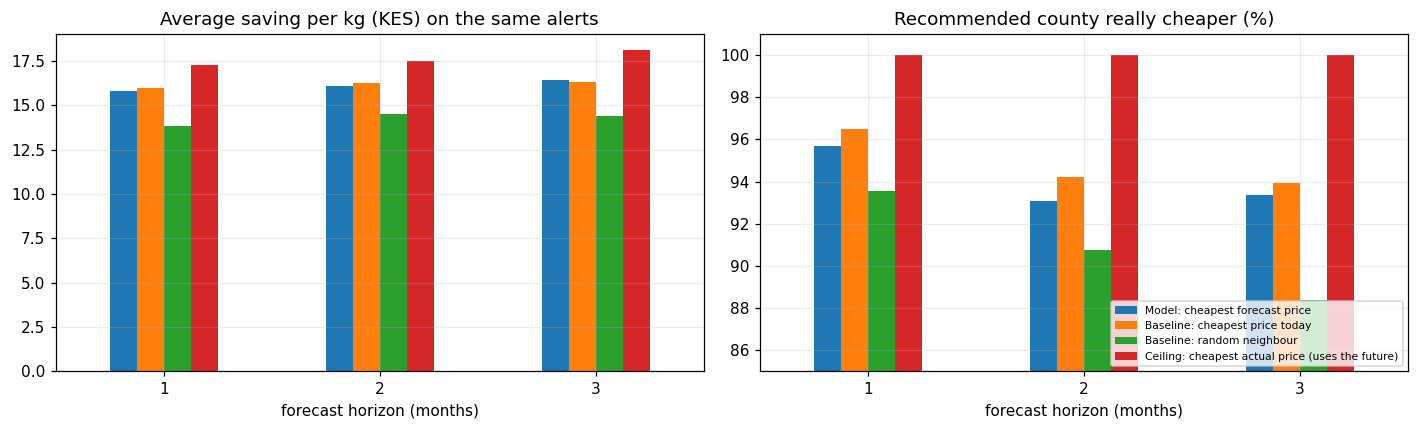

,mean,sd,n,std error
horizon,,,,
1,-0.15,1.73,371,0.09
2,-0.15,3.11,260,0.19
3,0.08,2.82,181,0.21


Same county picked by the forecast rule and by cheapest-today: 92.1%
Alerts scored: 812 | alert counties: 15 | median distance: 137 km | share where the alert county's price really rose more than 15%: 26.8%
By crop: {'Red Irish Potatoes': 352, 'Dry Maize': 238, 'Beans Rosecoco': 112, 'Sorghum': 110} | by price type: {'Wholesale': 695, 'Retail': 117}


In [12]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
w = res.pivot_table(index='horizon', columns='choice', values=['avg saving KES/kg', 'cheaper (hit rate %)'])
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
w['avg saving KES/kg'][list(STRATS.values())].plot.bar(ax=axs[0], rot=0, legend=False); axs[0].set_title('Average saving per kg (KES) on the same alerts'); axs[0].set_xlabel('forecast horizon (months)')
w['cheaper (hit rate %)'][list(STRATS.values())].plot.bar(ax=axs[1], rot=0); axs[1].set_ylim(85, 101); axs[1].set_title('Recommended county really cheaper (%)'); axs[1].set_xlabel('forecast horizon (months)')
axs[1].legend(fontsize=7, loc='lower right'); plt.tight_layout(); plt.show()
f_, n_ = picks['forecast'].loc[common], picks['now'].loc[common]
gain = pd.DataFrame({'extra saving of forecast pick over cheapest-today (KES/kg)': (f_.target_a - f_.target_b).values - (n_.target_a - n_.target_b).values,
                     'horizon': f_.reset_index().horizon.values}).groupby('horizon').agg(mean=('extra saving of forecast pick over cheapest-today (KES/kg)', 'mean'),
                     sd=('extra saving of forecast pick over cheapest-today (KES/kg)', 'std'), n=('horizon', 'size'))
gain['std error'] = gain.sd / np.sqrt(gain.n); display(gain.round(2))
print('Same county picked by the forecast rule and by cheapest-today:', f'{(f_.county_b.values == n_.county_b.values).mean():.1%}')
a_ = f_.reset_index()
print(f"Alerts scored: {len(a_)} | alert counties: {a_.county_a.nunique()} | median distance: {a_.km.median():.0f} km | share where the alert county's price really rose more than 15%: {((a_.target_a / a_.origin_a - 1) > .15).mean():.1%}")
print('By crop:', a_.commodity.value_counts().to_dict(), '| by price type:', a_.price_type.value_counts().to_dict())

In [13]:
fc_ = picks['forecast'].loc[common].reset_index()
print('Extra saving of the forecast pick over cheapest-today (KES/kg, mean +/- std error):', '; '.join(f'{h} month: {r["mean"]:.2f} +/- {r["std error"]:.2f}' for h, r in gain.iterrows()))
print(f'Forecast and cheapest-today pick the same county {(f_.county_b.values == n_.county_b.values).mean():.1%} of the time.')
yr = fc_.origin_month.dt.year.value_counts().sort_index(); print('Alerts by year:', yr.to_dict())
print(f'M8a alerts followed by a real rise of more than 15% in the alert county: {((fc_.target_a / fc_.origin_a - 1) > .15).mean():.1%}')

Extra saving of the forecast pick over cheapest-today (KES/kg, mean +/- std error): 1 month: -0.15 +/- 0.09; 2 month: -0.15 +/- 0.19; 3 month: 0.08 +/- 0.21
Forecast and cheapest-today pick the same county 92.1% of the time.
Alerts by year: {2015: 58, 2016: 79, 2017: 122, 2018: 138, 2019: 94, 2020: 28, 2021: 129, 2022: 98, 2023: 45, 2024: 21}
M8a alerts followed by a real rise of more than 15% in the alert county: 26.8%


**Reading the chart and the extra-saving table.** The model and "cheapest today" bars are almost the same height, and the model's extra saving is not above zero at any horizon.

**Who got alerts.** The printed lines show the mix of crops, price types and years. M8a alerts fire in many calm months by design (about 20% false alarms), so there are more of them than the earlier rule gave. **About a quarter of the scored alerts are followed by a real rise above 15%** in the alert county, in line with M8a's precision on the model card (22% / 32% / 39% at 1 / 2 / 3 months): an alert means higher risk, not a certain spike. The recommendation still saves money after a false alarm, because it is mostly exploiting county price gaps, not the spike itself.

## 5. Sensitivity: how big must the forecast gap be?
We change the minimum forecast gap (the recommended county must be this much cheaper than the alert county). A bigger gap gives fewer, safer recommendations.

In [14]:
rows = []
for mg in (0.0, 0.05, 0.10, 0.20):
    MIN_GAIN = mg
    r, _, _, c_ = evaluate(fc_arima, 'ARIMA', rule='m8a')
    r = r[r.choice.isin([STRATS['forecast'], STRATS['now']])].groupby('choice')[['cheaper (hit rate %)', 'avg saving KES/kg', 'avg saving %']].mean().round(2)
    r['min forecast gap'] = f'{mg:.0%}'; r['alerts scored (all horizons)'] = len(c_); rows.append(r.reset_index())
MIN_GAIN = 0.05
sens_tab = pd.concat(rows).set_index(['min forecast gap', 'choice']); display(sens_tab)

cheaper (hit rate %)  avg saving KES/kg  avg saving %  alerts scored (all horizons)
min forecast gap choice                                                                                                             
0%               Baseline: cheapest price today                 94.03              14.96         22.70                           916
                 Model: cheapest forecast price                 93.41              14.95         22.39                           916
5%               Baseline: cheapest price today                 94.88              16.18         24.52                           812
                 Model: cheapest forecast price                 94.04              16.11         24.07                           812
10%              Baseline: cheapest price today                 96.50              17.36         26.28                           724
                 Model: cheapest forecast price                 96.05              17.37         26.04                           724
20%              Baseline: cheapest price today                 97.80              19.97         30.57                           509
                 Model: cheapest forecast price                 97.64              19.97         30.30                           509

In [15]:
ORDER_ = ['0%', '5%', '10%', '20%']
h_ = sens_tab['cheaper (hit rate %)'].unstack('choice').loc[ORDER_]; n_al = sens_tab['alerts scored (all horizons)'].groupby(level=0).first()
for g_ in h_.index: print(f'min forecast gap {g_}: model cheaper {h_.loc[g_, STRATS["forecast"]]:.1f}% | cheapest-today {h_.loc[g_, STRATS["now"]]:.1f}% | alerts scored {n_al[g_]}')

min forecast gap 0%: model cheaper 93.4% | cheapest-today 94.0% | alerts scored 916
min forecast gap 5%: model cheaper 94.0% | cheapest-today 94.9% | alerts scored 812
min forecast gap 10%: model cheaper 96.0% | cheapest-today 96.5% | alerts scored 724
min forecast gap 20%: model cheaper 97.6% | cheapest-today 97.8% | alerts scored 509


**Reading it.** Requiring a bigger gap raises the hit rate for both the model and the baseline while the number of scored alerts falls. The model stays within about one point of the baseline throughout, so the conclusion does not depend on the 5% choice.

## 6. Does the saving survive the trip? (break-even)
Prices are per kg at the market. A buyer also pays to move the goods, so a saving only counts if it is larger than transport. **No freight rate is assumed from published data here**: I could not find a reliable published KES per tonne-km figure, so the cell works out the **break-even** instead, meaning how expensive transport can be before the saving is used up, using each alert's own saving and distance. The freight rates and trip costs in this section's tables are **illustrative only**; section 7 uses the government vehicle hire card instead.

In [16]:
# Does the saving survive the trip? No transport rate is assumed here: the cell works out the BREAK-EVEN, i.e. how expensive transport can be before the saving disappears.
RETURN_FACTOR = 2        # the truck is paid for the trip there and back
tr = picks['forecast'].loc[common].reset_index()
tr['saving_per_kg'] = tr.target_a - tr.target_b
tr['breakeven_per_tonne_km'] = tr.saving_per_kg * 1000 / (RETURN_FACTOR * tr.km)       # KES per tonne per km (charged both ways) at which the saving is exactly used up
q = tr.breakeven_per_tonne_km.quantile([.1, .5, .9]).round(0)
print(f'Mean saving KES {tr.saving_per_kg.mean():.1f}/kg = KES {tr.saving_per_kg.mean() * 1000:,.0f} per tonne | median distance {tr.km.median():.0f} km')
print(f'Break-even freight rate (KES per tonne-km, both ways): 10th percentile {q[.1]:.0f} | median {q[.5]:.0f} | 90th percentile {q[.9]:.0f}')
RATES = [10, 25, 50, 100, 150]      # ILLUSTRATIVE freight rates, KES per tonne-km: replace with a transporter quote
print('Share of alerts where the saving still beats transport, if freight costs this much per tonne-km (illustrative):')
display(pd.Series({f'KES {r}/tonne-km': (tr.breakeven_per_tonne_km > r).mean() for r in RATES}).mul(100).round(1).rename('% of alerts still saving money').to_frame().T)
TRIPS = [2000, 5000, 10000, 20000, 40000]      # ILLUSTRATIVE total cost of one round trip in KES (pick-up to lorry): replace with a quote
be = pd.DataFrame({'round trip cost (KES)': TRIPS}); be['break-even load (kg)'] = (be['round trip cost (KES)'] / tr.saving_per_kg.median()).round(0)
print('Smallest load that makes the median saving worth the trip:'); display(be.set_index('round trip cost (KES)').T)

Mean saving KES 16.0/kg = KES 16,041 per tonne | median distance 137 km
Break-even freight rate (KES per tonne-km, both ways): 10th percentile 7 | median 50 | 90th percentile 136
Share of alerts where the saving still beats transport, if freight costs this much per tonne-km (illustrative):


,KES 10/tonne-km,KES 25/tonne-km,KES 50/tonne-km,KES 100/tonne-km,KES 150/tonne-km
% of alerts still saving money,86.9,73.4,49.8,20.1,7.9


Smallest load that makes the median saving worth the trip:


round trip cost (KES),2000,5000,10000,20000,40000
break-even load (kg),145.0,362.0,723.0,1446.0,2892.0


**How to read it.**
* **Break-even rate:** the freight rate (KES per tonne per km, paid both ways) at which the saving is exactly used up. If a real quote is below the median break-even, most recommendations still save money for a **full lorry load**.
* **Break-even load:** the smallest load for which the median saving pays for one round trip. A small buyer moving one or two bags will not clear a trip cost of several thousand shillings, however large the saving per kg. **The recommendation is therefore for traders and institutions buying in bulk, not for individual households.**
* Savings are also reduced by handling losses, quality differences and market fees, which are not modelled.

## 7. Net saving after transport (vehicle and quantity)
A cheaper county is only worth it if the saving beats the cost of getting the goods there, and that depends on the **quantity**, the **vehicle** and the **distance**. For each vehicle we test loads of 10%, 25%, 50% and 100% of its capacity. A part-empty vehicle costs the same as a full one.
* **Price-only advice** is the earlier recommender (cheapest forecast price). The table shows how often it still saves money once transport is paid.
* **Net rule** picks the neighbour with the largest forecast saving after transport, and says "stay local" when nothing clears 5% of the forecast price.
* Hire rates come from the government dry-hire card, which may differ from what a transporter charges today; fuel use and driver/handling are assumptions. Read the pattern first, and replace the inputs with quotes before quoting figures.

kg  transport KES/kg (median trip)  price-only advice: still saves (%)  price-only: avg net KES/kg  \
vehicle                load                                                                                                          
Pickup 4x2 (1 t)       10%     100                           193.4                                 0.0                      -205.1   
                       25%     250                            77.4                                 0.5                       -72.4   
                       50%     500                            38.7                                 8.1                       -28.2   
                       100%   1000                            19.3                                29.4                        -6.1   
Flat-bed truck 2.5-5 t 10%     250                           108.8                                 0.2                      -108.5   
                       25%     625                            43.5                                 6.5                       -33.8   
                       50%    1250                            21.8                                26.0                        -8.9   
                       100%   2500                            10.9                                52.6                         3.6   
Flat-bed truck 5-7 t   10%     500                            69.5                                 1.0                       -63.7   
                       25%    1250                            27.8                                18.2                       -15.8   
                       50%    2500                            13.9                                44.3                         0.1   
                       100%   5000                             7.0                                68.5                         8.1   
Flat-bed truck 12 t    10%    1200                            37.7                                 8.9                       -27.2   
                       25%    3000                            15.1                                41.3                        -1.3   
                       50%    6000                             7.5                                66.0                         7.4   
                       100%  12000                             3.8                                82.6                        11.7   
Flat-bed truck 20 t    10%    2000                            31.9                                14.2                       -20.6   
                       25%    5000                            12.8                                47.3                         1.4   
                       50%   10000                             6.4                                71.7                         8.7   
                       100%  20000                             3.2                                84.7                        12.4   

                             net rule: alerts recommended (%)  net rule: still saves (%)  net rule: avg net KES/kg  net rule: scored  
vehicle                load                                                                                                           
Pickup 4x2 (1 t)       10%                                0.0                        NaN                       NaN                 0  
                       25%                                0.3                       16.7                     -25.2                 6  
                       50%                                2.7                       51.2                       1.6                41  
                       100%                              11.7                       71.1                       7.5               204  
Flat-bed truck 2.5-5 t 10%                                0.2                        0.0                     -40.3                 3  
                       25%                                2.1                       46.7                      -1.9                30  
   

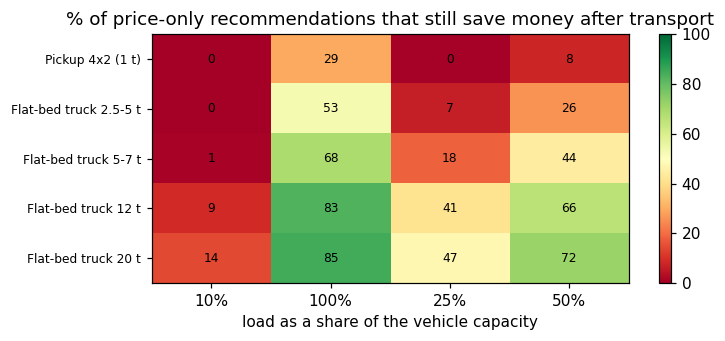

Median saving KES 13.8/kg, median road distance 160 km:


,smallest load that pays (kg),capacity (kg)
vehicle,,
Pickup 4x2 (1 t),NaN,1000
Flat-bed truck 2.5-5 t,1980.0,2500
Flat-bed truck 5-7 t,2530.0,5000
Flat-bed truck 12 t,3290.0,12000
Flat-bed truck 20 t,4640.0,20000


In [17]:
# NET saving after transport, for each vehicle and load. Cost of moving q kg a road distance d: trips x (hire + fuel + driver/handling), with trips = ceil(q / capacity),
#   hire = max(2d x hire rate per km, minimum charge); fuel = 2d x litres per km x pump price in the buyer's county; the vehicle is paid for the way back too.
# A part-empty vehicle costs as much as a full one. A recommendation must still save money AFTER this cost.
RETURN_FACTOR = 2
def transport_per_kg(road_km, qty, m, county=None, fuel_price=None):
    trips = np.ceil(qty / m.capacity_kg)
    if fuel_price is None: fuel_price = pd.Series(np.atleast_1d(np.asarray(county))).map(FUEL[m.fuel_type]).fillna(FUEL_NATIONAL[m.fuel_type]).values
    rt = np.asarray(road_km, dtype=float) * RETURN_FACTOR
    return trips * (np.maximum(rt * m.hire_rate_per_km, m.min_charge_per_trip) + rt * m.fuel_l_per_km * fuel_price + m.fixed_cost_per_trip) / qty
keys = GROUP + ['county_a']
base = picks['forecast'].loc[common].reset_index()                      # price-only picks (cheapest forecast), scored where both counties have a real target price
n_alerts_all = P_used.groupby(keys).ngroups
rows = []
for _, m in rates.iterrows():
    for share in (0.10, 0.25, 0.50, 1.00):
        qty = share * m.capacity_kg
        t = transport_per_kg(base.road_km, qty, m, base.county_a); net = base.target_a - base.target_b - t
        T = P_used.assign(tck=transport_per_kg(P_used.road_km, qty, m, P_used.county_a)); T['net_fc'] = T.fc_a - T.fc_b - T.tck
        Q = T[T.net_fc >= MIN_GAIN * T.fc_a]
        R = Q.loc[Q.groupby(keys).net_fc.idxmax().values] if len(Q) else Q
        S = R[R.obs_a & R.obs_b]; net2 = S.target_a - S.target_b - S.tck
        rows.append({'vehicle': m['mode'], 'load': f'{share:.0%}', 'kg': int(qty), 'transport KES/kg (median trip)': float(np.median(t)),
                     'price-only advice: still saves (%)': 100 * (net > 0).mean(), 'price-only: avg net KES/kg': net.mean(),
                     'net rule: alerts recommended (%)': 100 * len(R) / n_alerts_all, 'net rule: still saves (%)': 100 * (net2 > 0).mean() if len(S) else np.nan,
                     'net rule: avg net KES/kg': net2.mean() if len(S) else np.nan, 'net rule: scored': len(S)})
net_tab = pd.DataFrame(rows)
display(net_tab.round(1).set_index(['vehicle', 'load']))
import matplotlib.pyplot as plt
hm = net_tab.pivot(index='vehicle', columns='load', values='price-only advice: still saves (%)').reindex(rates['mode'])
fig, ax = plt.subplots(figsize=(7, 3.2)); im = ax.imshow(hm.values.astype(float), cmap='RdYlGn', vmin=0, vmax=100, aspect='auto'); ax.grid(False)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index, fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax.text(j, i, f'{hm.values[i, j]:.0f}', ha='center', va='center', fontsize=8)
ax.set_xlabel('load as a share of the vehicle capacity'); ax.set_title('% of price-only recommendations that still save money after transport'); plt.colorbar(im); plt.tight_layout(); plt.show()
# smallest load that makes the MEDIAN price-only saving pay for the median trip, per vehicle
med_s, med_km = (base.target_a - base.target_b).median(), base.road_km.median(); be_rows = []
for _, m in rates.iterrows():
    grid = np.arange(10, 3 * m.capacity_kg, 10); ok = grid[transport_per_kg(med_km, grid, m, fuel_price=FUEL_NATIONAL[m.fuel_type]) < med_s]
    be_rows.append({'vehicle': m['mode'], 'smallest load that pays (kg)': int(ok.min()) if len(ok) else np.nan, 'capacity (kg)': int(m.capacity_kg)})
be_tab = pd.DataFrame(be_rows).set_index('vehicle'); print(f'Median saving KES {med_s:.1f}/kg, median road distance {med_km:.0f} km:'); display(be_tab)

In [18]:
full = net_tab[net_tab.load == '100%'].set_index('vehicle'); tenth = net_tab[net_tab.load == '10%'].set_index('vehicle')
for v in rates['mode']:
    print(f'{v}: a full load saves money in {full.loc[v, "price-only advice: still saves (%)"]:.0f}% of price-only recommendations (average net KES {full.loc[v, "price-only: avg net KES/kg"]:.1f}/kg); '
          f'a 10% load saves money in {tenth.loc[v, "price-only advice: still saves (%)"]:.0f}% (average net KES {tenth.loc[v, "price-only: avg net KES/kg"]:.1f}/kg)')
print(f'Net rule vs price-only, over all vehicles and loads: net rule saves money in {net_tab["net rule: still saves (%)"].mean():.0f}% of the alerts it recommends on, price-only in {net_tab["price-only advice: still saves (%)"].mean():.0f}%; '
      f'the net rule recommends on {net_tab["net rule: alerts recommended (%)"].mean():.0f}% of alerts on average.')

Pickup 4x2 (1 t): a full load saves money in 29% of price-only recommendations (average net KES -6.1/kg); a 10% load saves money in 0% (average net KES -205.1/kg)
Flat-bed truck 2.5-5 t: a full load saves money in 53% of price-only recommendations (average net KES 3.6/kg); a 10% load saves money in 0% (average net KES -108.5/kg)
Flat-bed truck 5-7 t: a full load saves money in 68% of price-only recommendations (average net KES 8.1/kg); a 10% load saves money in 1% (average net KES -63.7/kg)
Flat-bed truck 12 t: a full load saves money in 83% of price-only recommendations (average net KES 11.7/kg); a 10% load saves money in 9% (average net KES -27.2/kg)
Flat-bed truck 20 t: a full load saves money in 85% of price-only recommendations (average net KES 12.4/kg); a 10% load saves money in 14% (average net KES -20.6/kg)
Net rule vs price-only, over all vehicles and loads: net rule saves money in 59% of the alerts it recommends on, price-only in 34%; the net rule recommends on 16% of alerts 

**How to read it (figures printed above)**
* **Quantity and vehicle decide.** A full flat-bed of 5 t or more saves money in roughly two thirds to 85% of the price-only recommendations, a full 2.5-5 t truck in about half, and a full 1 t pickup in under a third. A 10% load almost never pays (0 to 14%), because a part-empty trip costs the same.
* **Why the net rule helps small buyers:** it recommends on fewer alerts (about 16% on average), and a larger share of those still pay (59% against 34% for price-only). For the rest it says "stay local".
* **The smallest load that pays** answers "how much must I buy for the trip to be worth it": about 2 t on a 2.5-5 t truck, 2.5 t on a 5-7 t truck, 3.3 t on a 12 t truck and 4.6 t on a 20 t truck. A pickup never breaks even at the median saving and distance.
* Limits: 390 of 596 neighbour pairs have measured road km (the rest are straight-line x 1.3), and the hire card is dry-hire, undated and older than the market.

### 7b. If real transport prices differ from the card
The hire card is old and the fuel use is assumed, so the table below repeats the test with all transport costs 30% lower and 30% higher. Read it as a range: if the conclusion holds across the three columns (full loads pay, small loads do not), it does not depend on the exact rate. Replace with transporter quotes in `transport_quotes.csv` when available.

In [19]:
# What if real transport prices are 30% lower or higher than the card? Every transport cost is scaled; prices and distances stay the same.
rows = []
for scale, label in ((0.7, 'Low (-30%)'), (1.0, 'Base (card)'), (1.3, 'High (+30%)')):
    for _, m in rates.iterrows():
        for share in (0.5, 1.00):
            qty = share * m.capacity_kg
            t = scale * transport_per_kg(base.road_km, qty, m, base.county_a)
            rows.append({'case': label, 'vehicle': m['mode'], 'load': f'{share:.0%}', 'price-only still saves (%)': 100 * ((base.target_a - base.target_b - t) > 0).mean()})
sens = pd.DataFrame(rows).pivot_table(index=['vehicle', 'load'], columns='case', values='price-only still saves (%)')[['Low (-30%)', 'Base (card)', 'High (+30%)']]
display(sens.round(0).reindex(rates['mode'], level=0))
be = []
for scale, label in ((0.7, 'Low (-30%)'), (1.0, 'Base (card)'), (1.3, 'High (+30%)')):
    for _, m in rates.iterrows():
        grid = np.arange(10, 3 * m.capacity_kg, 10); ok = grid[scale * transport_per_kg(med_km, grid, m, fuel_price=FUEL_NATIONAL[m.fuel_type]) < med_s]
        be.append({'case': label, 'vehicle': m['mode'], 'kg': int(ok.min()) if len(ok) else np.nan})
display(pd.DataFrame(be).pivot(index='vehicle', columns='case', values='kg')[['Low (-30%)', 'Base (card)', 'High (+30%)']].reindex(rates['mode']).rename_axis(columns='smallest load that pays (kg)'))

case                         Low (-30%)  Base (card)  High (+30%)
vehicle                load                                      
Pickup 4x2 (1 t)       100%        46.0         29.0         21.0
                       50%         19.0          8.0          4.0
Flat-bed truck 2.5-5 t 100%        66.0         53.0         44.0
                       50%         41.0         26.0         17.0
Flat-bed truck 5-7 t   100%        78.0         68.0         59.0
                       50%         56.0         44.0         33.0
Flat-bed truck 12 t    100%        87.0         83.0         78.0
                       50%         76.0         66.0         56.0
Flat-bed truck 20 t    100%        89.0         85.0         82.0
                       50%         80.0         72.0         63.0

smallest load that pays (kg),Low (-30%),Base (card),High (+30%)
mode,,,
Pickup 4x2 (1 t),990.0,NaN,NaN
Flat-bed truck 2.5-5 t,1390.0,1980.0,NaN
Flat-bed truck 5-7 t,1770.0,2530.0,3290.0
Flat-bed truck 12 t,2310.0,3290.0,4280.0
Flat-bed truck 20 t,3250.0,4640.0,6040.0


## 8. What the user would see
The function below is the dashboard card: the user enters a county, crop, price type, month, horizon, quantity and vehicle. Distance and prices are looked up. The examples use real alerts from the backtest.

In [20]:
def advise(county, commodity, price_type, origin_month, horizon, qty_kg, vehicle):
    """The card a dashboard user would see: inputs are the county, crop, price type, month, horizon, quantity and vehicle. Distance and fuel price are looked up, not typed."""
    m = rates[rates['mode'] == vehicle].iloc[0]; om = pd.Timestamp(origin_month)
    g = (forecasts[(forecasts.model == 'ARIMA') & (forecasts.commodity == commodity) & (forecasts.price_type == price_type) & (forecasts.origin_month == om) & (forecasts.horizon == horizon)])
    a = g[g.county == county]
    if a.empty: return print('No forecast for that county, crop, month and horizon.')
    a = a.iloc[0]
    print(f'{county} | {commodity} ({price_type}) | forecast from {om:%Y-%m}, {horizon} month(s) ahead | {qty_kg:,} kg by {vehicle}')
    print(f'  Price now KES {a.origin_price:.2f}/kg | forecast KES {a.forecast_price:.2f}/kg ({a.forecast_price / a.origin_price - 1:+.1%}) | spike probability {a.prob:.0%} | alert: {"YES" if a.alert else "no"}')
    c = pairs[pairs.county_a == county].merge(g.rename(columns={'county': 'county_b'}), on='county_b')
    c = c[c.origin_observed]                                          # only counties with a real price at the origin month
    if c.empty: return print('  No nearby county with a real price this month.')
    c = c.assign(transport=transport_per_kg(c.road_km, qty_kg, m, c.county_a)); c['net'] = a.forecast_price - c.forecast_price - c.transport
    b = c.loc[c.net.idxmax()]
    if b.net < MIN_GAIN * a.forecast_price:
        gain_txt = f'saves only KES {b.net:.2f}/kg' if b.net > 0 else f'would cost KES {-b.net:.2f}/kg MORE'
        return print(f'  Stay local: the best nearby option is {b.county_b}, but after transport (KES {b.transport:.2f}/kg) it {gain_txt}.')
    print(f'  Buy in {b.county_b}: price KES {b.forecast_price:.2f}/kg | {b.road_km:.0f} km by road | transport KES {b.transport:.2f}/kg | NET saving KES {b.net:.2f}/kg = KES {b.net * qty_kg:,.0f} in total')
ex = picks['forecast'].loc[common].reset_index().sort_values(['origin_month', 'county_a'])
ex = ex[ex.price_type == 'Wholesale'].drop_duplicates('county_a').head(3)      # the first alerts in time, not picked by outcome
for _, r in ex.iterrows():
    for q, v in ((200, 'Pickup 4x2 (1 t)'), (5000, 'Flat-bed truck 5-7 t')): advise(r.county_a, r.commodity, r.price_type, r.origin_month, int(r.horizon), q, v); print()

Kisumu | Red Irish Potatoes (Wholesale) | forecast from 2015-01, 2 month(s) ahead | 200 kg by Pickup 4x2 (1 t)
  Price now KES 31.68/kg | forecast KES 34.61/kg (+9.3%) | spike probability 37% | alert: YES
  Stay local: the best nearby option is Uasin Gishu, but after transport (KES 96.70/kg) it would cost KES 93.48/kg MORE.

Kisumu | Red Irish Potatoes (Wholesale) | forecast from 2015-01, 2 month(s) ahead | 5,000 kg by Flat-bed truck 5-7 t
  Price now KES 31.68/kg | forecast KES 34.61/kg (+9.3%) | spike probability 37% | alert: YES
  Stay local: the best nearby option is Nakuru, but after transport (KES 8.09/kg) it would cost KES 3.57/kg MORE.

Kitui | Sorghum (Wholesale) | forecast from 2015-01, 1 month(s) ahead | 200 kg by Pickup 4x2 (1 t)
  Price now KES 50.00/kg | forecast KES 50.00/kg (-0.0%) | spike probability 11% | alert: YES
  Stay local: the best nearby option is Nairobi, but after transport (KES 102.96/kg) it would cost KES 93.82/kg MORE.

Kitui | Sorghum (Wholesale) | forec

## 9. Decision log (recommender)
| # | Decision | Evidence | Why |
|---|---|---|---|
| R1 | Build a **"where to buy"** recommender, not "what to buy instead". | The data has the same crop in many counties; crop substitution would need an outside nutrition table and only has four crops. | It is the version the data supports. "What to buy instead" is a possible extension. |
| R2 | Only the four crops with a chosen ARIMA order; wholesale and retail kept apart. | Harness `ORDERS`. | Same models as the group table, and prices of different types are not comparable. |
| R3 | "Nearby" = county centres within 200 km. | 596 pairs, median 15 neighbours per county. | Gives every county at least one neighbour without crossing the country. Road distance is not available. |
| R4 | Alert = **M8a's alert** (probability of a rise above 15% above the frozen threshold per horizon), rebuilt for each backtest year. | Same model and thresholds as the hand-over script; the reproduction check matches the model card. The earlier rank-based rule gives the same conclusion. | The recommender must match the alerts the dashboard shows. |
| R5 | Recommend only counties with a **real price at the alert month**; score only where both have a real price at the target month. | Observed targets are 7.4% of rows. | Estimated prices are partly copied from neighbouring counties, so comparing them would be circular. |
| R6 | Minimum forecast gap 5%. | Sensitivity table, 0% to 20%. | Result is stable; 5% keeps most alerts. |
| R7 | Judge the forecast against **cheapest today** on identical alerts. | Extra saving is small and within its standard error (section 4). | The question is whether the forecast adds value, not whether moving to a cheaper county saves money. |
| R8 | Backtest 2015-2024 only; 2025-26 untouched. | Group rule: the test opens once on Day 5. | Nothing here is chosen from the test window. |
| R9 | Test transport with a **break-even** analysis, not an assumed freight rate. | No reliable published KES per tonne-km figure was found. | The conclusion does not depend on a number we cannot source; rates in the tables are placeholders. |
| R10 | Add a **transport cost model** (supervisor request, session of 2 Nov): vehicle, load, fuel use per km, fuel price, other cost per km, fixed cost per trip, return trip paid. Inputs are read from `govt_vehicle_hire_rates.csv` and `fuel_prices_by_county.csv`; optional `transport_quotes.csv` overrides vehicles. | Hire rates: government dry-hire card (undated). Fuel: EPRA county caps (15 Oct to 14 Nov 2026). Fuel use (L/km) and driver/handling (KES 1,000 per trip) are **assumptions**. | The user needs a net saving, not a price gap. A part-empty vehicle costs the same as a full one, so quantity matters. |
| R11 | Road distance comes from `county_road_distance.csv` (1994 matrix, 41 of 47 counties); missing pairs use straight-line x 1.3. | 390 of 596 neighbour pairs are measured. | Better than straight-line only; the matrix is old, so treat it as indicative. |
| R12 | A **net rule** recommends the neighbour with the largest forecast saving after transport, only if that is at least 5% of the alert county's forecast price; otherwise "stay local". | Section 7 compares it with the price-only pick. | The supervisor's example: for a small purchase the model should say do not travel. |

## Summary and limits
**Result.** After an M8a spike alert, pointing a buyer to a cheaper nearby county is right in almost every scored case and saves roughly a quarter of the price in the 2015-2024 backtest (exact figures printed in section 4). **The forecast contributes nothing to that.** "Cheapest nearby county today" does as well or slightly better, and the ARIMA forecast changes the pick only about 8% of the time.

**What to say.** "We tested a recommender that suggests a cheaper nearby market when the model raises an alert. It works, but because county prices differ a lot and the gaps last, not because the forecast is clever. For the dashboard the simplest rule, the cheapest nearby county today, is as good as using the forecast. After transport, the saving holds for bulk buyers but not for small ones."

**Limits.**
* The scored alerts come from a few counties, mostly wholesale, mostly earlier years.
* Savings are price differences between counties and exclude handling, quality and market fees. Transport is covered by the break-even analysis (section 6) and by the vehicle model in section 7, whose hire rates come from the government dry-hire rate card (fuel use and driver/handling are assumptions) until real transporter quotes are loaded.
* Only real (observed) prices are scored, so the recommender is evaluated where county prices are actually reported.
* Alerts mean higher risk: only about a quarter are followed by a real rise above 15%.

**After transport.** Section 7 turns the price gap into a net saving for a chosen vehicle and quantity. Using government hire rates, a full flat-bed of 5 t or more still saves money in about two thirds to 85% of recommendations, a pickup in under a third, and a 10% load almost never; the net rule says "stay local" when the trip is not worth it. Fuel use and driver/handling are assumptions and the hire card is old, so transporter quotes should replace them before any figure is quoted.

